In [1]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pathlib
from torch.utils.data import Subset

In [2]:
pathToModels = pathlib.Path("models")
pathToData = pathlib.Path("data")
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
trainDataset = datasets.FashionMNIST(root=pathToData, train=True, download=True, transform=ToTensor())
testDataset = datasets.FashionMNIST(root=pathToData, train=False, download=True, transform=ToTensor())

trainLoader = torch.utils.data.DataLoader(trainDataset, batch_size=BATCH_SIZE, shuffle=True)
testLoader = torch.utils.data.DataLoader(testDataset, batch_size=BATCH_SIZE, shuffle=False)

In [9]:
trainDataset[0][0].min(), trainDataset[0][0].max()

(tensor(0.), tensor(1.))

In [4]:
len(trainDataset), len(testDataset)

(60000, 10000)

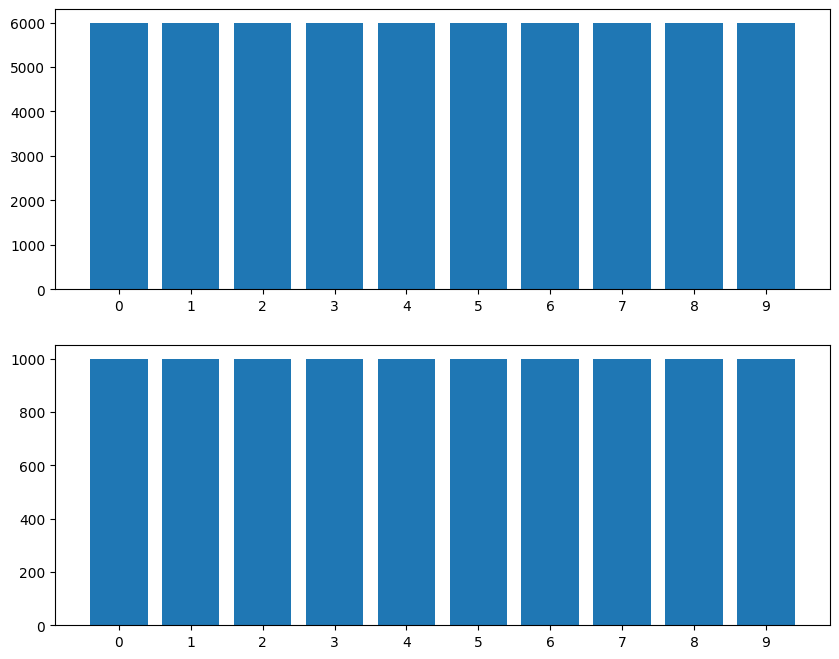

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(10, 8)) 

trainCounts = np.bincount([y for _, y in trainDataset])
axs[0].bar(range(len(trainCounts)), trainCounts)
axs[0].set_xticks(range(len(trainCounts)))

testCounts = np.bincount([y for _, y in testDataset])
axs[1].bar(range(len(testCounts)), testCounts)
axs[1].set_xticks(range(len(testCounts)))

plt.show()

In [6]:
from models.fashionMnist.model import fashionMnistModel
from utils import *

In [ ]:
data

In [7]:
model = fashionMnistModel()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model = train(model, trainLoader, testLoader, optimizer, criterion, DEVICE, 10, 'fashionMnist')

Epoch 1/10 - Train Loss: 0.0091, Train Accuracy: 0.7892 - Test Loss: 0.0057, Test Accuracy: 0.8667
Epoch 2/10 - Train Loss: 0.0059, Train Accuracy: 0.8632 - Test Loss: 0.0049, Test Accuracy: 0.8836
Epoch 3/10 - Train Loss: 0.0051, Train Accuracy: 0.8825 - Test Loss: 0.0045, Test Accuracy: 0.8954
Epoch 4/10 - Train Loss: 0.0046, Train Accuracy: 0.8922 - Test Loss: 0.0042, Test Accuracy: 0.9023
Epoch 5/10 - Train Loss: 0.0042, Train Accuracy: 0.9018 - Test Loss: 0.0041, Test Accuracy: 0.9043
Epoch 6/10 - Train Loss: 0.0039, Train Accuracy: 0.9090 - Test Loss: 0.0040, Test Accuracy: 0.9084
Epoch 7/10 - Train Loss: 0.0037, Train Accuracy: 0.9142 - Test Loss: 0.0037, Test Accuracy: 0.9125
Epoch 8/10 - Train Loss: 0.0035, Train Accuracy: 0.9194 - Test Loss: 0.0038, Test Accuracy: 0.9148
Epoch 9/10 - Train Loss: 0.0032, Train Accuracy: 0.9237 - Test Loss: 0.0037, Test Accuracy: 0.9146
Epoch 10/10 - Train Loss: 0.0031, Train Accuracy: 0.9286 - Test Loss: 0.0037, Test Accuracy: 0.9168


In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

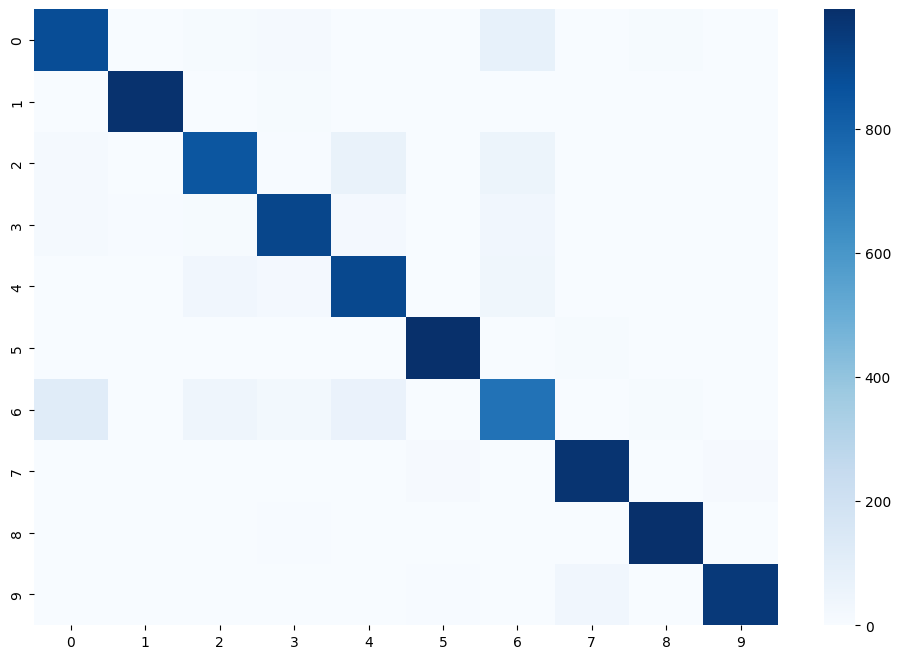

In [9]:
y_true = []
y_pred = []
model.eval()
with torch.no_grad():
    for images, labels in testLoader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, cmap='Blues')
    
plt.show()